<a href="https://colab.research.google.com/github/dhruvdabas/SIT725_s226545091/blob/main/SIT719_Task2_1P_basic_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIT719 Analytics for Security and Privacy
## Pass Task 2.1: Basic scripting with Python
***SIT719, Dhruv Dabas (226545091), Trimester 3, 2026***

## Section 1

### Step 1. Import the pandas and numpy libraries

In [1]:
import pandas as pd
import numpy as np

### Step 2. Import the iris dataset and check the header

In [2]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'
iris = pd.read_csv(url)
iris.head()

,5.1,3.5,1.4,0.2,Iris-setosa
0,4.9,3.0,1.4,0.2,Iris-setosa
1,4.7,3.2,1.3,0.2,Iris-setosa
2,4.6,3.1,1.5,0.2,Iris-setosa
3,5.0,3.6,1.4,0.2,Iris-setosa
4,5.4,3.9,1.7,0.4,Iris-setosa


### Step 3. Create the 5 column heads and display them
The file has no header row, so `read_csv` used the first flower as the column names. Reading it again with `header=None` and `names=...` keeps all 150 rows and adds the 5 column heads.

In [3]:
column_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']
iris = pd.read_csv(url, header=None, names=column_names)

print("Column headers:", list(iris.columns))
print("Shape:", iris.shape)
iris.head()

Column headers: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']
Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### Step 4. Check if there are any missing values in the dataframe

In [4]:
print("Any missing values?", iris.isnull().values.any())
print("\nMissing values per column:")
print(iris.isnull().sum())

Any missing values? False

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
class           0
dtype: int64


### Step 5. Set rows 10 to 29 of the column 'petal_length' to NaN

In [5]:
iris.loc[10:29, 'petal_length'] = np.nan

# show the rows around the change (9 and 30 are unchanged)
iris.loc[[9, 10, 11, 28, 29, 30]]

,sepal_length,sepal_width,petal_length,petal_width,class
9,4.9,3.1,1.5,0.1,Iris-setosa
10,5.4,3.7,NaN,0.2,Iris-setosa
11,4.8,3.4,NaN,0.2,Iris-setosa
28,5.2,3.4,NaN,0.2,Iris-setosa
29,4.7,3.2,NaN,0.2,Iris-setosa
30,4.8,3.1,1.6,0.2,Iris-setosa


### Step 6. Check again for missing values and count them

In [6]:
print("Any missing values?", iris.isnull().values.any())
print("\nMissing values per column:")
print(iris.isnull().sum())
print("\nTotal missing values:", iris.isnull().sum().sum())

Any missing values? True

Missing values per column:
sepal_length     0
sepal_width      0
petal_length    20
petal_width      0
class            0
dtype: int64

Total missing values: 20


### Step 7. Substitute the NaN values with 10.0

In [7]:
iris['petal_length'] = iris['petal_length'].fillna(10.0)

print("Total missing values now:", iris.isnull().sum().sum())
iris.loc[[9, 10, 11, 28, 29, 30]]

Total missing values now: 0


,sepal_length,sepal_width,petal_length,petal_width,class
9,4.9,3.1,1.5,0.1,Iris-setosa
10,5.4,3.7,10.0,0.2,Iris-setosa
11,4.8,3.4,10.0,0.2,Iris-setosa
28,5.2,3.4,10.0,0.2,Iris-setosa
29,4.7,3.2,10.0,0.2,Iris-setosa
30,4.8,3.1,1.6,0.2,Iris-setosa


## Section 2 examples

**Example 1: NaN check.** `isnull().sum()` counts missing values per column (shown in Steps 4 and 6).

**Example 2: slicing with iloc.** `iloc` selects rows and columns by position. Here: the first 5 rows and the first 2 columns.

In [8]:
iris.iloc[0:5, 0:2]

,sepal_length,sepal_width
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6


**Visualisation with matplotlib.** A scatter plot of petal length against petal width, one colour per species, using a fresh copy of the data.

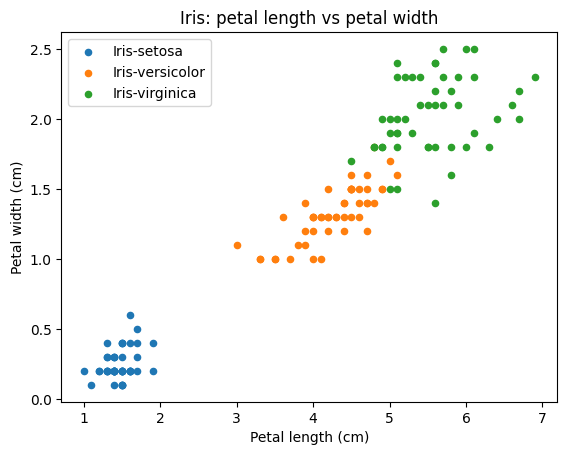

In [9]:
import matplotlib.pyplot as plt

clean = pd.read_csv(url, header=None, names=column_names)
for species, group in clean.groupby('class'):
    plt.scatter(group['petal_length'], group['petal_width'], label=species, s=20)

plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.title('Iris: petal length vs petal width')
plt.legend()
plt.show()